# 05 — Spatial analysis

Use all four processed datasets; run independently after notebooks 00 → 01. No user-selected state or crop.

Tables retain all available years; charts choose the latest shared year automatically. Calendar climate is descriptive context, not a crop-season feature.

Read the calculation cells first: group rows, calculate totals/means, and check counts. Chart formatting and file saving can be read afterward.

In [1]:
from pathlib import Path
import os
import numpy as np
import pandas as pd
from IPython.display import display

current = Path.cwd().resolve()
# Find the project folder, starting from the notebook's current folder.
for folder in [current, *current.parents]:
    if (folder / "data/processed").is_dir() and (folder / "notebooks").is_dir():
        project_root = folder
        break
else:
    raise FileNotFoundError("Start this notebook inside the project folder.")
os.environ["MPLCONFIGDIR"] = str(project_root / ".cache/matplotlib")
import matplotlib.pyplot as plt

processed_dir = project_root / "data/processed"

output_dir = processed_dir / "eda/spatial_all_datasets"
output_dir.mkdir(parents=True, exist_ok=True)

Read every processed dataset.

In [2]:
crop_df = pd.read_csv(processed_dir / "crop_yield.csv")
rain_df = pd.read_csv(processed_dir / "precipitation.csv")
vegetation_df = pd.read_csv(processed_dir / "vegetation.csv")
geography_df = pd.read_csv(processed_dir / "geography.csv")

Check source coverage and observation keys.

In [3]:
datasets = {"Crop yield": crop_df, "Rainfall": rain_df,
            "Vegetation": vegetation_df, "Geography": geography_df}
summary_rows = []
for name, frame in datasets.items():
    district_count = len(frame[["state", "district"]].drop_duplicates())
    summary_rows.append({"dataset": name, "rows": len(frame),
                         "states": frame["state"].nunique(), "districts": district_count})
source_summary = pd.DataFrame(summary_rows)
display(source_summary)
assert not crop_df.duplicated(["state", "district", "year", "crop_name", "season"]).any()
assert not rain_df.duplicated(["state", "district", "Date"]).any()
assert not vegetation_df.duplicated(["state", "district", "date"]).any()

,dataset,rows,states,districts
0,Crop yield,286784,26,399
1,Rainfall,1490016,26,408
2,Vegetation,127725,26,513
3,Geography,784562,35,594


Compare district availability across sources; geography has no time dimension.

,Crop yield,Rainfall,Vegetation,Geography
state,,,,
Andhra Pradesh,12,13,23,23
Assam,11,13,23,23
Bihar,36,34,37,37
Chandigarh,1,1,1,1
Chhattisgarh,4,7,16,16
Goa,2,2,2,2
Gujarat,18,17,25,25
Haryana,16,17,19,19
Himachal Pradesh,12,12,12,12


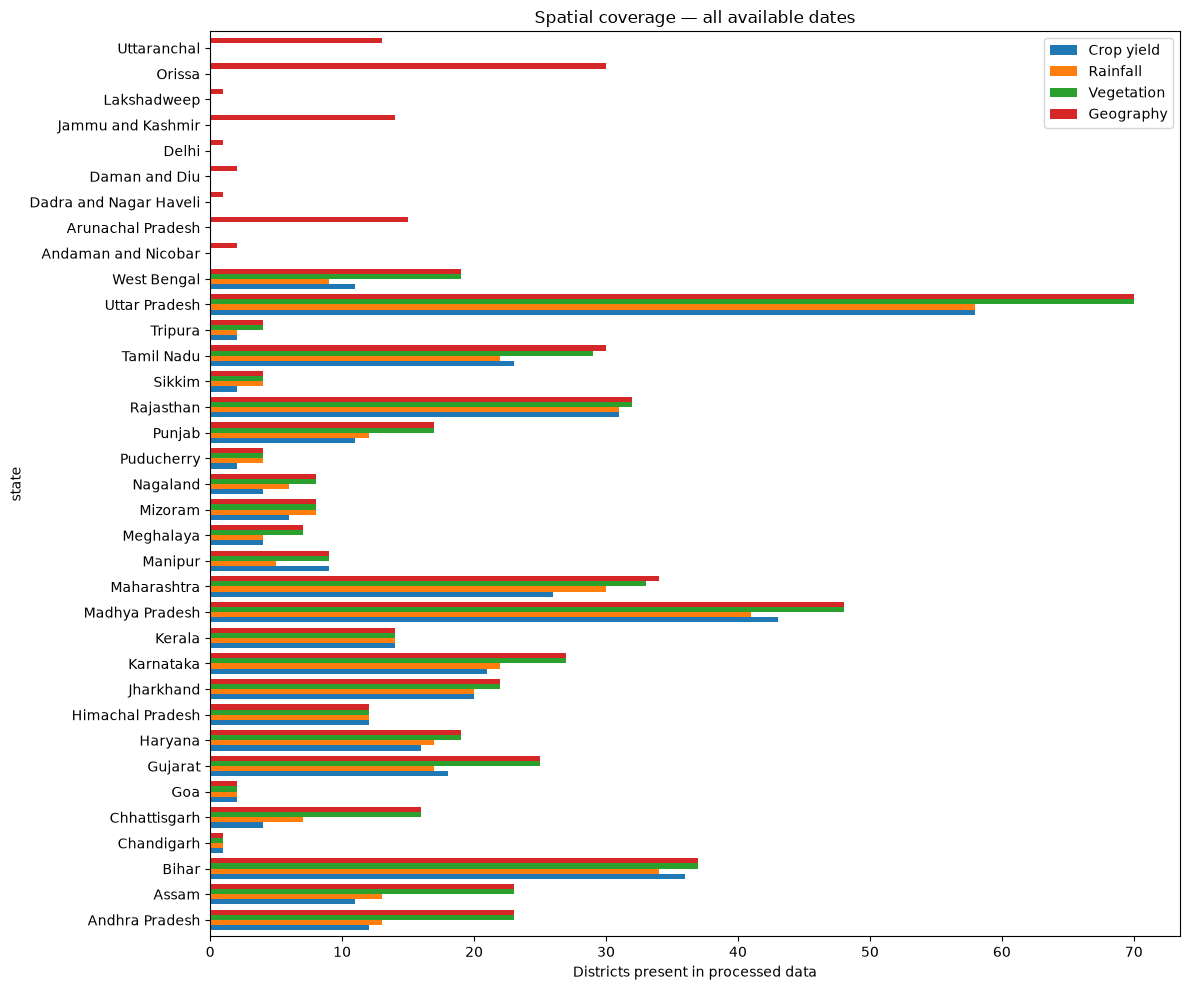

In [4]:
coverage_parts = []
for name, frame in datasets.items():
    counts = frame[["state", "district"]].drop_duplicates().groupby("state").size().rename(name)
    coverage_parts.append(counts)
state_coverage = pd.concat(coverage_parts, axis=1).fillna(0).astype(int)
display(state_coverage)
ax = state_coverage.plot.barh(figsize=(12, 10), width=0.8)
ax.set(xlabel="Districts present in processed data", title="Spatial coverage — all available dates")
plt.tight_layout()
plt.savefig(output_dir / "01_state_coverage.png", dpi=150)
plt.show()

Compute crop yields; drop the 'Total' season (it repeats other seasons) and crops not measured in tonnes, keeping every other crop/season category separate.

In [5]:
year_parts = crop_df["year"].str.extract(r"^(\d{4})-(\d{4})$").apply(pd.to_numeric, errors="coerce")
crop_df["crop_year"] = year_parts[0]
valid_year = year_parts[1] == year_parts[0] + 1
valid_numbers = np.isfinite(crop_df["area"]) & np.isfinite(crop_df["production"])
valid_amounts = (crop_df["area"] > 0) & (crop_df["production"] >= 0)
valid_units = (crop_df["area_unit"] == "Hectare") & (crop_df["production_unit"] == "Tonnes")
non_tonne_crops = ["Coconut", "Cotton(Lint)", "Kapas", "Jute", "Mesta", "Jute & Mesta", "Sannhamp"]
valid_season = crop_df["season"] != "Total"  # "Total" repeats the sum of the other seasons
valid_crop = (valid_year & valid_numbers & valid_amounts & valid_units & valid_season
              & ~crop_df["crop_name"].isin(non_tonne_crops))
print("Crop rows excluded from yield calculations:", int((~valid_crop).sum()))
crop_df = crop_df.loc[valid_crop].copy()
crop_df["crop_year"] = crop_df["crop_year"].astype(int)
crop_df["yield_t_ha"] = crop_df["production"] / crop_df["area"]
# Keep crop names and seasons separate; a shared crop_code is not enough to merge them.

Crop rows excluded from yield calculations: 43290


Calculate annual district rainfall only when every calendar day has a valid measurement.

In [6]:
rain_df["date"] = pd.to_datetime(rain_df["Date"], errors="coerce")
rain_df["rain_mm"] = pd.to_numeric(rain_df["Precipitation_mm"], errors="coerce")
invalid_rain = ~np.isfinite(rain_df["rain_mm"]) | (rain_df["rain_mm"] < 0)
rain_df.loc[invalid_rain, "rain_mm"] = np.nan
print("Unusable rain dates:", rain_df["date"].isna().sum(), "Missing rain values:", rain_df["rain_mm"].isna().sum())
rain_df = rain_df.dropna(subset=["date"]).copy()
assert not rain_df.duplicated(["state", "district", "date"]).any()

rain_df["calendar_year"] = rain_df["date"].dt.year
rain_annual = rain_df.groupby(["state", "district", "calendar_year"], as_index=False).agg(
    observed_days=("rain_mm", "count"), observed_rain_mm=("rain_mm", lambda values: values.sum(min_count=1))
)
year_start = pd.to_datetime(rain_annual["calendar_year"].astype(str) + "-01-01")
rain_annual["expected_days"] = 365 + year_start.dt.is_leap_year.astype(int)
complete_year = rain_annual["observed_days"] == rain_annual["expected_days"]
rain_annual["rain_mm"] = rain_annual["observed_rain_mm"]
rain_annual.loc[~complete_year, "rain_mm"] = np.nan

Unusable rain dates: 0 Missing rain values: 0


Use source-approved vegetation values and retain missing data.

In [7]:
vegetation_df["date"] = pd.to_datetime(vegetation_df["date"], errors="coerce")
vegetation_df["period_end"] = pd.to_datetime(vegetation_df["period_end"], errors="coerce")
approved_by_source = vegetation_df["quality_status"] == "valid"
valid_ndvi = vegetation_df["ndvi_mean"].between(-1, 1)
valid_fraction = vegetation_df["valid_crop_fraction"].between(0, 1)
valid_interval = vegetation_df["period_end"] > vegetation_df["date"]
usable = approved_by_source & valid_ndvi & valid_fraction & valid_interval
vegetation_df["ndvi_used"] = vegetation_df["ndvi_mean"].where(usable)
vegetation_df["evi_used"] = vegetation_df["evi_mean"].where(usable & np.isfinite(vegetation_df["evi_mean"]))
# Use the source's valid flag; do not add the old 0.6 fraction or five-composite gate.
# These are available-observation means, not complete-period/model-ready features.

Average available composites by district/year, keeping usable counts and the observed date range.

In [8]:
vegetation_df["calendar_year"] = vegetation_df["date"].dt.year
vegetation_annual = vegetation_df.groupby(["state", "district", "calendar_year"], as_index=False).agg(
    observed_composites=("date", "size"), usable_composites=("ndvi_used", "count"),
    ndvi_mean=("ndvi_used", "mean"), evi_mean=("evi_used", "mean"),
    first_observation=("date", "min"), last_observation=("date", "max")
)
vegetation_annual["usable_share"] = vegetation_annual["usable_composites"] / vegetation_annual["observed_composites"]
ndvi_quality = vegetation_df.groupby("quality_status", dropna=False).agg(
    rows=("date", "size"), ndvi_present=("ndvi_mean", "count"), usable_ndvi=("ndvi_used", "count")
).reset_index()
display(ndvi_quality)

,quality_status,rows,ndvi_present,usable_ndvi
0,low_valid_crop_fraction,40464,0,0
1,missing_source_image,1026,0,0
2,no_mapped_cropland,1528,0,0
3,no_valid_pixels,11874,0,0
4,valid,72833,72833,72833


Automatically select the latest shared year with complete rainfall somewhere; individual gaps stay visible.

In [9]:
crop_years = set(crop_df["crop_year"].unique())
rain_years = set(rain_annual.loc[rain_annual["rain_mm"].notna(), "calendar_year"])
vegetation_years = set(vegetation_annual["calendar_year"])
shared_years = crop_years & rain_years & vegetation_years
if not shared_years:
    raise ValueError("No common year exists across the three observation datasets.")
comparison_year = int(max(shared_years))
crop_latest = crop_df.loc[crop_df["crop_year"] == comparison_year].copy()
rain_latest = rain_annual.loc[rain_annual["calendar_year"] == comparison_year].copy()
vegetation_latest = vegetation_annual.loc[vegetation_annual["calendar_year"] == comparison_year].copy()
print(f"Crop label: {comparison_year}-{comparison_year + 1}; climate: calendar {comparison_year}.")
print("These periods are not assumed to be identical crop seasons.")

Crop label: 2022-2023; climate: calendar 2022.
These periods are not assumed to be identical crop seasons.


Compare state yields for the four largest crop/season groups by area; only states with ≥3 districts are charted, and all groups are saved.

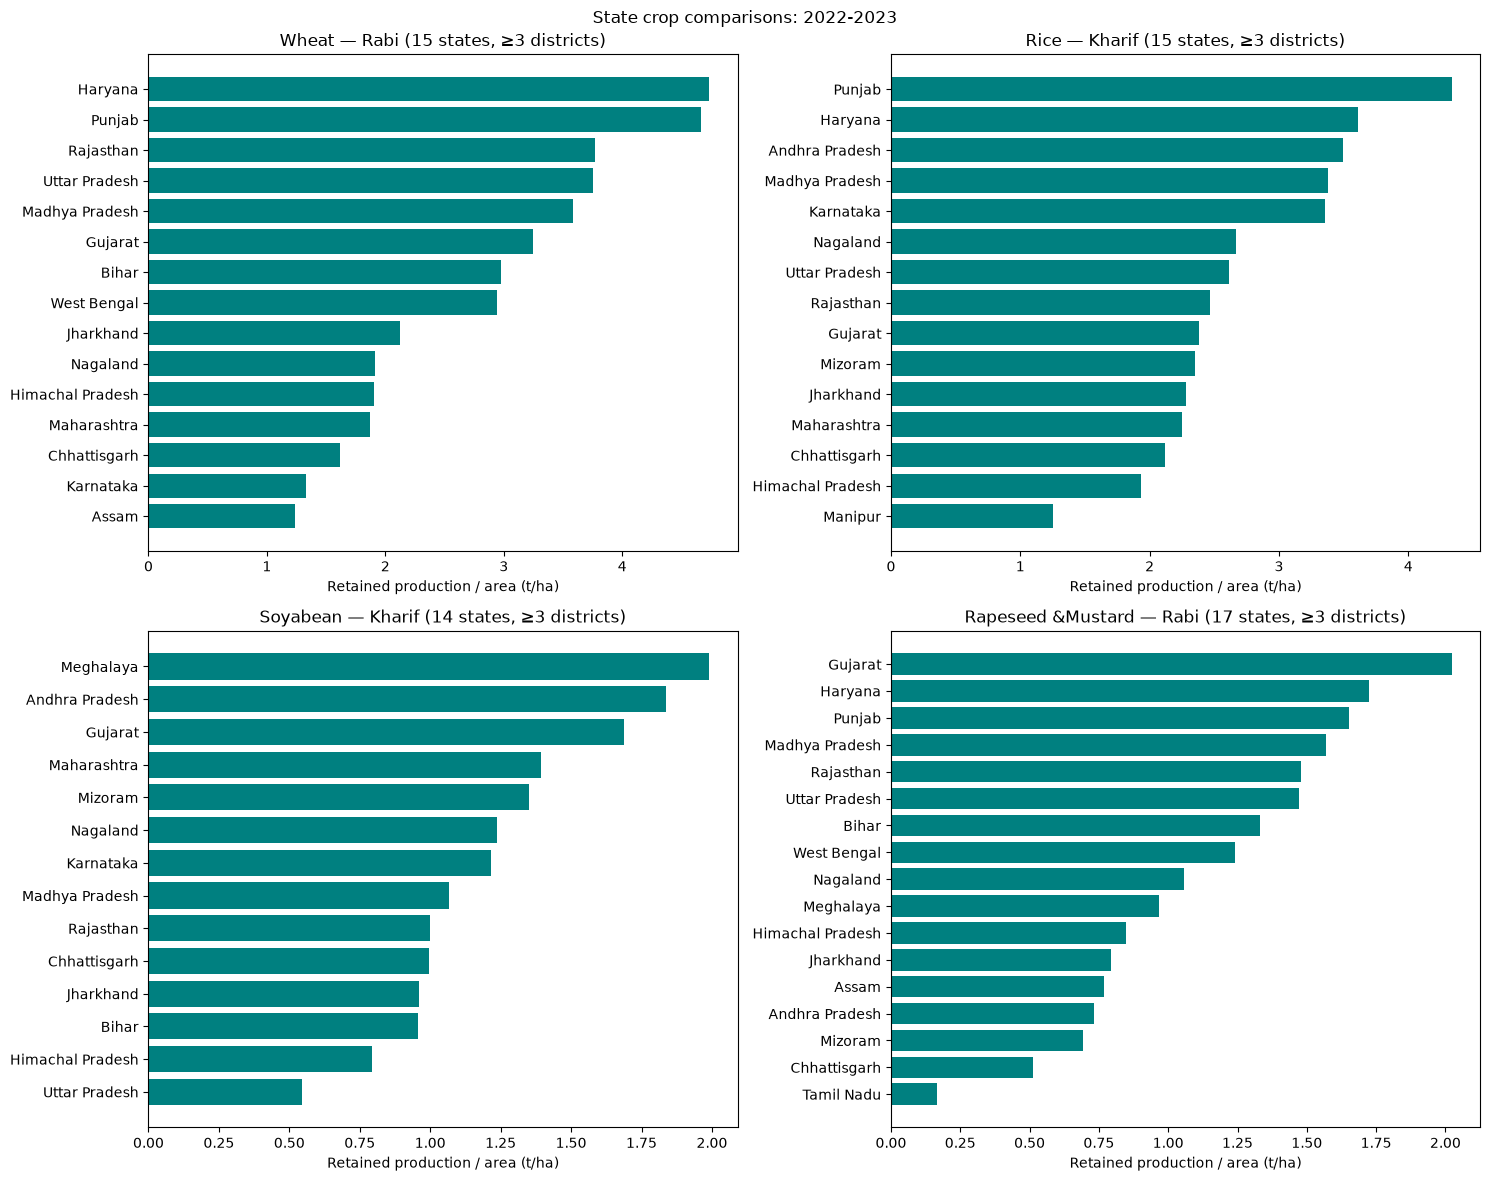

In [10]:
crop_state = crop_latest.groupby(["state", "crop_name", "season"], as_index=False).agg(
    area_ha=("area", "sum"), production_t=("production", "sum"), districts=("district", "nunique")
)
crop_state["yield_t_ha"] = crop_state["production_t"] / crop_state["area_ha"]
# Rank groups by retained cultivated area; the district threshold applies only to charts.
top_groups = crop_state.groupby(["crop_name", "season"])["area_ha"].sum().nlargest(4).index
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
for ax, (crop, season) in zip(axes.flat, top_groups):
    values = crop_state.loc[(crop_state["crop_name"] == crop) & (crop_state["season"] == season)
                            & (crop_state["districts"] >= 3)].sort_values("yield_t_ha")
    ax.barh(values["state"], values["yield_t_ha"], color="teal")
    ax.set(title=f"{crop} — {season} ({len(values)} states, ≥3 districts)",
           xlabel="Retained production / area (t/ha)")
    if values.empty:
        ax.text(0.5, 0.5, "No states have ≥3 retained districts", transform=ax.transAxes, ha="center")
for ax in axes.flat[len(top_groups):]:
    ax.set_visible(False)
fig.suptitle(f"State crop comparisons: {comparison_year}-{comparison_year + 1}")
fig.tight_layout()
fig.savefig(output_dir / "02_crop_state_comparisons.png", dpi=150)
plt.show()

Use mean boundary vertices as approximate district markers; these are not validated centroids or area weights.

In [11]:
valid_points = geography_df["Latitude"].between(-90, 90) & geography_df["Longitude"].between(-180, 180)
print("Invalid coordinate rows excluded:", int((~valid_points).sum()))
locations = geography_df.loc[valid_points].groupby(["state", "district"], as_index=False).agg(
    latitude=("Latitude", "mean"), longitude=("Longitude", "mean")
)
map_data = locations.merge(rain_latest, on=["state", "district"], how="left", validate="one_to_one")
map_data = map_data.merge(vegetation_latest.drop(columns="calendar_year"), on=["state", "district"],
    how="left", validate="one_to_one")
map_data["calendar_year"] = comparison_year
print("Geography markers:", len(map_data), "Rain values:", map_data["rain_mm"].notna().sum(),
      "NDVI values:", map_data["ndvi_mean"].notna().sum())

Invalid coordinate rows excluded: 0
Geography markers: 594 Rain values: 408 NDVI values: 505


Map available rainfall and NDVI; grey crosses mean missing values and NDVI means have unequal observation counts.

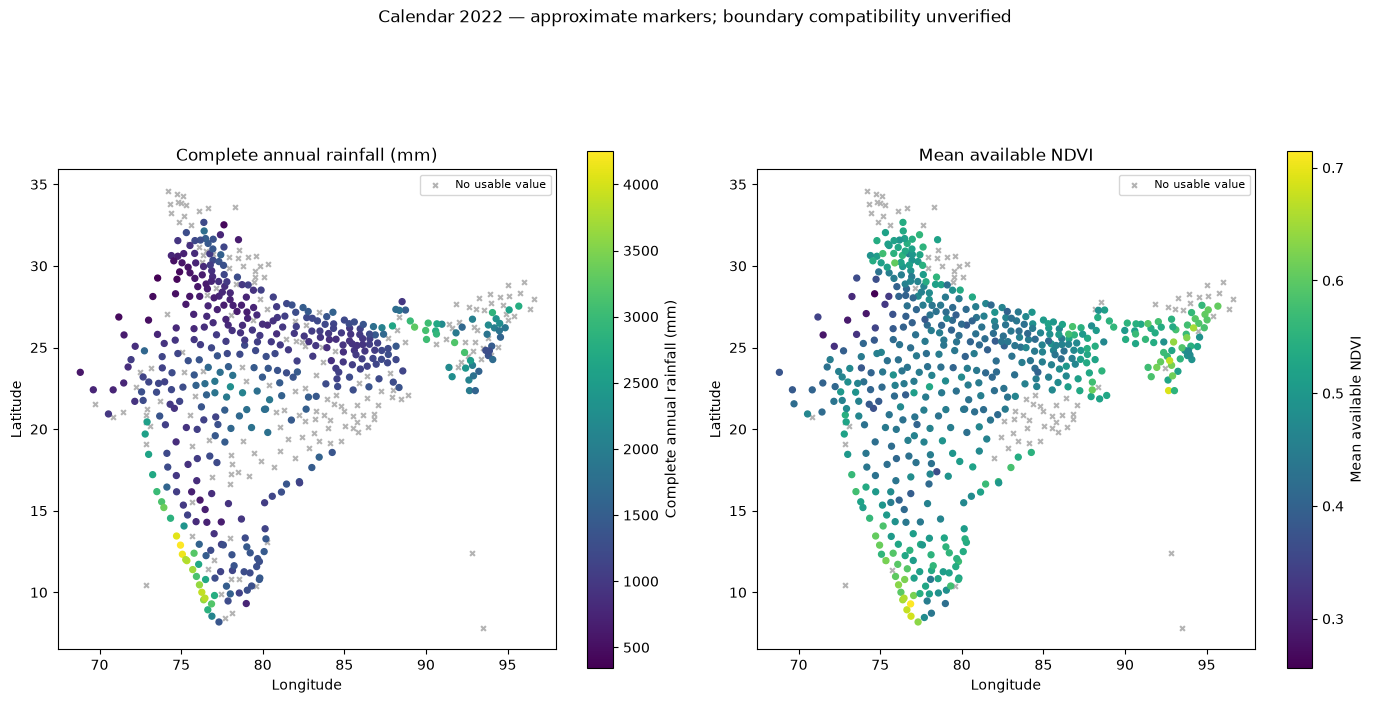

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(14, 8))
for ax, column, label in zip(axes, ["rain_mm", "ndvi_mean"], ["Complete annual rainfall (mm)", "Mean available NDVI"]):
    present = map_data[column].notna()
    ax.scatter(map_data.loc[~present, "longitude"], map_data.loc[~present, "latitude"],
        marker="x", color="0.7", s=12, label="No usable value")
    points = ax.scatter(map_data.loc[present, "longitude"], map_data.loc[present, "latitude"],
        c=map_data.loc[present, column], cmap="viridis", s=18)
    fig.colorbar(points, ax=ax, label=label, shrink=0.7)
    ax.set(title=label, xlabel="Longitude", ylabel="Latitude", aspect="equal")
    ax.legend(fontsize=8)
fig.suptitle(f"Calendar {comparison_year} — approximate markers; boundary compatibility unverified")
fig.tight_layout()
fig.savefig(output_dir / "03_district_climate_maps.png", dpi=150)
plt.show()

Compare district climate values and usable NDVI counts; calculate descriptive rainfall–NDVI correlation on paired districts.

In [13]:
district_comparison = rain_latest.merge(vegetation_latest, on=["state", "district", "calendar_year"],
    how="outer", validate="one_to_one")
state_comparison = district_comparison.groupby("state", as_index=False).agg(
    district_records=("district", "nunique"), complete_rain_districts=("rain_mm", "count"),
    ndvi_districts=("ndvi_mean", "count"), mean_district_rain_mm=("rain_mm", "mean"),
    mean_district_ndvi=("ndvi_mean", "mean"), usable_composites=("usable_composites", "sum")
)
display(state_comparison)
display(district_comparison[["state", "district", "rain_mm", "ndvi_mean", "usable_composites", "observed_composites"]].head(15))

paired_climate = district_comparison[["rain_mm", "ndvi_mean"]].dropna()
rain_ndvi_r = paired_climate["rain_mm"].corr(paired_climate["ndvi_mean"])
print(f"Rainfall–NDVI Pearson r: {rain_ndvi_r:.3f}; paired districts: {len(paired_climate)}")
# Descriptive association only; no causal, yield or spatial-dependence test.

,state,district_records,complete_rain_districts,ndvi_districts,mean_district_rain_mm,mean_district_ndvi,usable_composites
0,Andhra Pradesh,23,13,23,1196.738462,0.491125,279
1,Assam,23,13,23,2568.276923,0.564117,290
2,Bihar,37,34,37,1177.722059,0.483293,380
3,Chandigarh,1,1,1,1019.960000,0.451896,15
4,Chhattisgarh,16,7,16,1443.050000,0.439170,214
5,Goa,2,2,2,3265.290000,0.516232,26
6,Gujarat,25,17,25,1118.200588,0.450751,387
7,Haryana,19,17,19,770.102941,0.455319,304
8,Himachal Pradesh,12,12,11,1205.773333,0.530876,223
9,Jharkhand,22,20,22,1140.305000,0.467220,298


,state,district,rain_mm,ndvi_mean,usable_composites,observed_composites
0,Andhra Pradesh,Adilabad,NaN,0.491924,12,23
1,Andhra Pradesh,Anantapur,653.71,0.441130,12,23
2,Andhra Pradesh,Chittoor,1233.76,0.528712,16,23
3,Andhra Pradesh,Cuddapah,964.11,0.463327,11,23
4,Andhra Pradesh,East Godavari,1356.31,0.569079,12,23
5,Andhra Pradesh,Guntur,1157.82,0.475940,10,23
6,Andhra Pradesh,Hyderabad,NaN,0.365893,8,23
7,Andhra Pradesh,Karimnagar,NaN,0.495706,17,23
8,Andhra Pradesh,Khammam,NaN,0.520677,16,23
9,Andhra Pradesh,Krishna,1304.59,0.519777,7,23


Rainfall–NDVI Pearson r: 0.627; paired districts: 400


Save all district-year tables and the automatically selected comparison; never fill missing NDVI with zero.

In [14]:
assert vegetation_annual.loc[vegetation_annual["usable_composites"] == 0, "ndvi_mean"].isna().all()
assert not district_comparison.duplicated(["state", "district", "calendar_year"]).any()
tables_to_save = {"source_summary": source_summary, "state_coverage": state_coverage.reset_index(),
    "crop_district_year": crop_df, "rain_district_year": rain_annual,
    "vegetation_district_year": vegetation_annual, "crop_state_comparison": crop_state,
    "ndvi_quality": ndvi_quality, "district_comparison": district_comparison,
    "state_comparison": state_comparison, "map_data": map_data}
for name, frame in tables_to_save.items():
    frame.to_csv(output_dir / f"{name}.csv", index=False)
print("Saved all-dataset spatial outputs:", output_dir.relative_to(project_root))

Saved all-dataset spatial outputs: data/processed/eda/spatial_all_datasets
